# 案例一 · 新零售智能销售

## 1.读取数据

In [1]:
import pandas as pd
data4 = pd.read_csv('data8/订单表2025-4.csv', encoding='gbk')
data5 = pd.read_csv('data8/订单表2025-5.csv', encoding='gbk')
data6 = pd.read_csv('data8/订单表2025-6.csv', encoding='gbk')
data7 = pd.read_csv('data8/订单表2025-7.csv', encoding='gbk')
data8 = pd.read_csv('data8/订单表2025-8.csv', encoding='gbk')
data9 = pd.read_csv('data8/订单表2025-9.csv', encoding='gbk')
goods_info = pd.read_excel('data8/商品表.xlsx')
print(data4.shape, data5.shape, data6.shape, data7.shape,
      data8.shape, data9.shape, goods_info.shape)

(2077, 14) (46068, 14) (51925, 14) (77644, 14) (86459, 14) (86723, 14) (3626, 8)


## 2.处理无人售货机数据

In [2]:
data = pd.concat([data4, data5, data6, data7, data8, data9], ignore_index=True)
print('订单表合并后的形状为', data.shape)

订单表合并后的形状为 (350896, 14)


In [3]:
print('订单表各列的缺失值数目为：\n', data.isnull().sum())

订单表各列的缺失值数目为：
 设备编号         0
下单时间         0
订单编号         0
购买数量(个)      0
手续费(元)       0
总金额(元)       0
支付状态         0
出货状态         3
收款方        276
退款金额(元)      0
购买用户         0
商品详情         0
省市区          0
软件版本         0
dtype: int64


In [4]:
# 删除缺失值
print('未做删除缺失值前订单表行列数目为：', data.shape)
data = data.dropna(how='any')  # 删除
print('删除完缺失值后订单表行列数目为：', data.shape)

未做删除缺失值前订单表行列数目为： (350896, 14)


删除完缺失值后订单表行列数目为：

 (350617, 14)


In [5]:
# 清洗商品表
print('商品表各列的缺失值数目为：\n', goods_info.isnull().sum())
# 删除缺失值
print('未做删除缺失值前商品表行列数目为：', goods_info.shape)
goods_info = goods_info.dropna(how='any')
print('删除完缺失值后商品表行列数目为：', goods_info.shape)

商品表各列的缺失值数目为：
 商品名称      392
销售数量        0
销售金额        0
利润          0
库存数量        0
进货数量        0
存货周转天数      0
月份          0
dtype: int64
未做删除缺失值前商品表行列数目为： (3626, 8)
删除完缺失值后商品表行列数目为： (3234, 8)


In [6]:
# 从省市区中提取市的信息，并创建新列
data['市'] = data['省市区'].str[3: 6]
print('经过处理后前5行为：\n', data.head())

经过处理后前5行为：
      设备编号             下单时间                    订单编号  购买数量(个)  手续费(元)  总金额(元)  \
0  112531  2025/4/30 22:55  112531qr15251001151105        1    0.03     2.5   
1  112673  2025/4/30 22:50  112673qr15250998551741        1    0.05     5.0   
2  112636  2025/4/30 22:35  112636qr15250989343846        1    0.03     3.0   
3  112636  2025/4/30 22:33  112636qr15250988245087        1    0.04     4.0   
4  112636  2025/4/30 21:33  112636qr15250952296930        1    0.04     4.0   

  支付状态  出货状态    收款方  退款金额(元)                          购买用户        商品详情  \
0   微信  出货成功  鑫零售结算      0.0  os-xL0q3NG6YFG7PJrF2x7QaS23E     可口可乐X1;   
1   微信  出货成功  鑫零售结算      0.0  ooCjVwAX4b9Mj-Fa569zuID-BZas     旺仔牛奶X1;   
2  支付宝  出货成功  鑫零售结算      0.0  os-xL0sMR9v0hm349m56wzMxVacU  雪碧330MLX1;   
3  支付宝  出货成功  鑫零售结算      0.0  os-xL0lF3FKQU_ejpHt39CJCsmfc    阿萨姆奶茶X1;   
4   微信  出货成功  鑫零售结算      0.0  os-xL0h0eKDIjcN88h9OFsBlaIcY      王老吉X1;   

         省市区                       软件版本    市  
0     广东省中山市         

In [7]:
# 定义一个需剔除的字符的list
error_str = [' ', '(', ')', '（', '）', '0', '1', '2', '3', '4', '5', '6',
             '7', '8', '9', 'g', 'l', 'm', 'M', 'L', '听', '特', '饮', '罐',
             '瓶', '只', '装', '欧', '式', '&', '%', 'X', 'x', ';']
# 使用循环剔除指定字符
for i in error_str:
    data['商品详情'] = data['商品详情'].str.replace(i, '')
# 新建一列 商品名称用于新数据存放
data['商品名称'] = data['商品详情']
data['商品名称'][0: 5]

0     可口可乐
1     旺仔牛奶
2       雪碧
3    阿萨姆奶茶
4      王老吉
Name: 商品名称, dtype: object

In [8]:
# 删除金额较少的订单前的数据量
print(data.shape)
# 删除金额较少的订单后的数据量
data = data[data['总金额(元)'] >= 0.5]
print(data.shape)

(350617, 16)
(350450, 16)


In [9]:
# 将商品名称表中的部分商品进行名字统一
goods_info['商品名称'] = goods_info['商品名称'].str.replace('可口可乐', '可乐')
goods_info['商品名称'] = goods_info['商品名称'].str.replace(' ', '')
goods_info['商品名称'] = goods_info['商品名称'].str.replace('可比克薯片烧烤味',
                                                    '可比克烧烤味')
goods_info['商品名称'] = goods_info['商品名称'].str.replace('可比克薯片牛肉味',
                                                    '可比克牛肉味')
goods_info['商品名称'] = goods_info['商品名称'].str.replace('可比克薯片番茄味',
                                                    '可比克番茄味')
goods_info['商品名称'] = goods_info['商品名称'].str.replace('阿沙姆奶茶',
                                                    '阿萨姆奶茶')
goods_info['商品名称'] = goods_info['商品名称'].str.replace('罐装百威',
                                                    '罐装百威啤酒')
print(goods_info['商品名称'])
goods_info.to_csv('tmp/goods_info.csv', index=False, encoding = 'gbk')

0           黑派黑水
1           黑派黑水
2           黑派黑水
3           黑派黑水
4           黑派黑水
          ...   
3229    18g旺仔小馒头
3230    18g旺仔小馒头
3231    18g旺仔小馒头
3232    18g旺仔小馒头
3233    18g旺仔小馒头
Name: 商品名称, Length: 3234, dtype: object


In [10]:
# 降维订单数据
data = data.drop(['手续费(元)', '收款方', '软件版本', '省市区',
                  '商品详情', '退款金额(元)'], axis=1)
print('降维后，数据列为：\n', data.columns.values)

降维后，数据列为：
 ['设备编号' '下单时间' '订单编号' '购买数量(个)' '总金额(元)' '支付状态' '出货状态' '购买用户' '市' '商品名称']


In [11]:
# 归约订单数据字段
# 将时间格式的字符串转换为标准的时间
data['下单时间'] = pd.to_datetime(data['下单时间'])
data['小时'] = data['下单时间'].dt.hour  # 提取时间中的小时，将其赋给新列 小时
data['月份'] = data['下单时间'].dt.month
data['下单时间段'] = 'time'  # 新增一列下单时间段，并将其初始化为time
exp1 = data['小时'] <= 5  # 判断小时是否小于等于5
# 条件为真则时间段为凌晨
data.loc[exp1, '下单时间段'] = '凌晨'
# 判断小时是否大于5且小于等于8
exp2 = (5 < data['小时']) & (data['小时'] <= 8)
# 条件为真则时间段为早晨
data.loc[exp2, '下单时间段'] = '早晨'
# 判断小时是否大于8且小于等于11
exp3 = (8 < data['小时']) & (data['小时'] <= 11)
# 条件为真则时间段为上午
data.loc[exp3, '下单时间段'] = '上午'
# 判断小时是否小大于11且小于等于13
exp4 = (11 < data['小时']) & (data['小时'] <= 13)
# 条件为真则时间段为中午
data.loc[exp4, '下单时间段'] = '中午'
# 判断小时是否大于13且小于等于16
exp5 = (13 < data['小时']) & (data['小时'] <= 16)
# 条件为真则时间段为下午
data.loc[exp5, '下单时间段'] = '下午'
# 判断小时是否大于16且小于等于19
exp6 = (16 < data['小时']) & (data['小时'] <= 19)
# 条件为真则时间段为傍晚
data.loc[exp6, '下单时间段'] = '傍晚'
# 判断小时是否大于19且小于等于24
exp7 = (19 < data['小时']) & (data['小时'] <= 24)
# 条件为真则时间段为晚上
data.loc[exp7, '下单时间段'] = '晚上'
print('处理完成后的订单表前5行为：\n', data.head())
data.to_csv('tmp/order.csv', index=False, encoding = 'gbk')

处理完成后的订单表前5行为：


      设备编号                下单时间                    订单编号  购买数量(个)  总金额(元) 支付状态  \
0  112531 2025-04-30 22:55:00  112531qr15251001151105        1     2.5   微信   
1  112673 2025-04-30 22:50:00  112673qr15250998551741        1     5.0   微信   
2  112636 2025-04-30 22:35:00  112636qr15250989343846        1     3.0  支付宝   
3  112636 2025-04-30 22:33:00  112636qr15250988245087        1     4.0  支付宝   
4  112636 2025-04-30 21:33:00  112636qr15250952296930        1     4.0   微信   

   出货状态                          购买用户    市   商品名称  小时  月份 下单时间段  
0  出货成功  os-xL0q3NG6YFG7PJrF2x7QaS23E  中山市   可口可乐  22   4    晚上  
1  出货成功  ooCjVwAX4b9Mj-Fa569zuID-BZas  佛山市   旺仔牛奶  22   4    晚上  
2  出货成功  os-xL0sMR9v0hm349m56wzMxVacU  广州市     雪碧  22   4    晚上  
3  出货成功  os-xL0lF3FKQU_ejpHt39CJCsmfc  广州市  阿萨姆奶茶  22   4    晚上  
4  出货成功  os-xL0h0eKDIjcN88h9OFsBlaIcY  广州市    王老吉  21   4    晚上  


## 3.绘制可视化图形

### 3.1 销售额和新零售智能销售设备数量之间的关系

In [12]:
%matplotlib inline
import pandas as pd
import numpy as np
from pyecharts.charts import Line
from pyecharts import options as opts
import matplotlib.pyplot as plt
from pyecharts.charts import Bar
from pyecharts.charts import Pie
from pyecharts.charts import Grid

In [13]:
data = pd.read_csv('tmp/order.csv', encoding='gbk')

In [14]:
def f(x):
    return len(list(set((x.values))))
groupby1 = data.groupby(by='月份', as_index=False).agg(
    {'设备编号': f, '总金额(元)': 'sum'})
groupby1.columns = ['月份', '设备数量', '销售额']
line = (Line()
        .add_xaxis([str(i) for i in groupby1['月份'].values.tolist()])
        .add_yaxis('销售额', np.round(groupby1['销售额'].values.tolist(), 2))
        .add_yaxis('设备数量', groupby1['设备数量'].values.tolist(), yaxis_index=1)
        .set_series_opts(label_opts=opts.LabelOpts(is_show=True, 
                                                   position='top',
                                                   font_size=10))
        .set_global_opts(
            xaxis_opts=opts.AxisOpts(
            name='月份', name_location='center', name_gap=25), 
            title_opts=opts.TitleOpts(
            title='销售额和新零售智能销售设备数量之间的关系'), 
            yaxis_opts=opts.AxisOpts(
                name='销售额（元）', name_location='center', name_gap=60, 
                axislabel_opts=opts.LabelOpts(
                formatter='{value}')))
        .extend_axis(
            yaxis=opts.AxisOpts(
                name='设备数量（台）', name_location='center', name_gap=40, 
                axislabel_opts=opts.LabelOpts(
                formatter='{value}'), interval=50))
        )
#line.render_notebook()
line.render("3.1.html")

'C:\\Users\\LENOVN\\Desktop\\pppp\\课堂作业\\3.1.html'

### 3.2 订单数量与新零售智能销售设备数量的关系

<Figure size 1000x400 with 0 Axes>

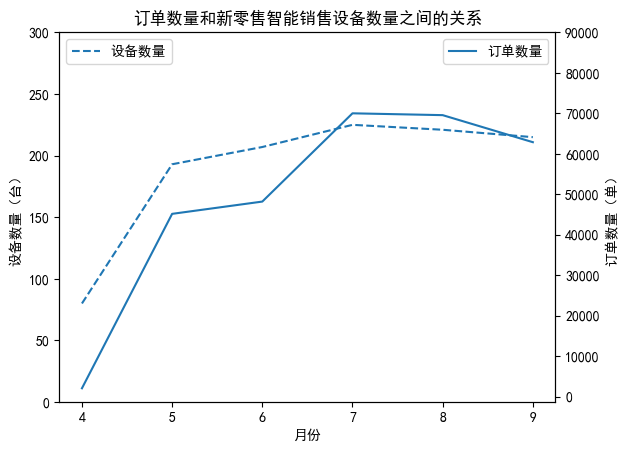

In [15]:
# 订单量和新零售智能销售设备数量的关系
groupby2 = data.groupby(by='月份', as_index=False).agg(
    {'设备编号': f, '订单编号': f})
groupby2.columns = ['月份', '设备数量', '订单数量']
# 绘制图形
plt.figure(figsize=(10, 4))
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax1 = plt.subplots()  # 使用subplots函数创建窗口
ax1.plot(groupby2['月份'], groupby2['设备数量'], '--')
ax1.set_yticks(range(0, 350, 50))  # 设置y1轴的刻度范围
ax1.legend(('设备数量',), loc='upper left', fontsize=10)
ax2 = ax1.twinx()  # 创建第二个坐标轴
ax2.plot(groupby2['月份'], groupby2['订单数量'])
ax2.set_yticks(range(0, 100000, 10000))  # 设置y2轴的刻度范围
ax2.legend(('订单数量',), loc='upper right', fontsize=10)
ax1.set_xlabel('月份')
ax1.set_ylabel('设备数量（台）')
ax2.set_ylabel('订单数量（单）')
plt.title('订单数量和新零售智能销售设备数量之间的关系')
plt.show()

### 3.3 各市新零售智能销售设备的平均销售总额

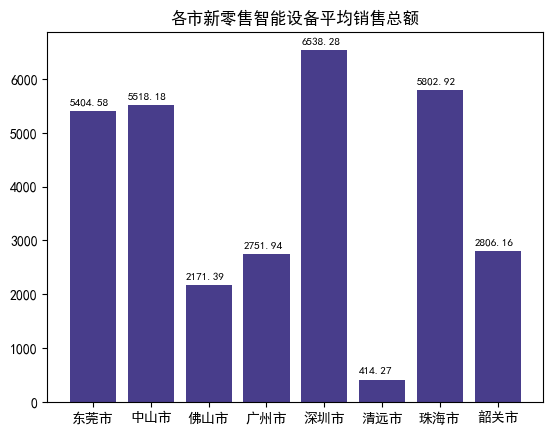

In [16]:
# 各城市新零售智能设备平均销售总额条形图
gruop3 = data.groupby(by='市', as_index=False).agg({'总金额(元)':'sum', '设备编号':f})
gruop3['销售总额'] = np.round(gruop3['总金额(元)'], 2)
gruop3['平均销售总额'] = np.round(gruop3['销售总额'] / gruop3['设备编号'], 2)
plt.bar(gruop3['市'].values.tolist(), gruop3['平均销售总额'].values.tolist(), 
        color='#483D8B')
# 给条形图添加数据标注
for x, y in enumerate(gruop3['平均销售总额'].values):
    plt.text(x - 0.4, y + 100, '%s' %y, fontsize=8)
plt.title('各市新零售智能设备平均销售总额')
plt.show()

### 3.4 畅销商品 TOP10

In [ ]:
# 销售金额前10的商品及其金额
group4 = data.groupby(by='商品名称', as_index=False)['总金额(元)'].sum()
group4.sort_values(by='总金额(元)', ascending=False, inplace=True)
d = group4.iloc[: 10]
x_data = d['商品名称'].values.tolist()
y_data = np.round(d['总金额(元)'].values, 2).tolist()
bar = (Bar()
       .add_xaxis(x_data)
       .add_yaxis('', y_data, color='#CD853F')
       .set_global_opts(title_opts=opts.TitleOpts(title='畅销前10的商品'),
                        xaxis_opts=opts.AxisOpts(
                            type_='category', name_rotate='45',
                            axislabel_opts={'interval': '0'})))
#bar.render_notebook()
bar.render("3.4.html")

### 3.5 滞销商品 BOTTOM10

In [ ]:
# 销售金额后10的商品及其金额
group4 = data.groupby(by='商品名称', as_index=False)['总金额(元)'].sum()
group4.sort_values(by='总金额(元)', ascending=False, inplace=True)
d = group4.iloc[-10: ]
x_data = d['商品名称'].values.tolist()
y_data = np.round(d['总金额(元)'].values, 2).tolist()
bar = (Bar()
       .add_xaxis(x_data)
       .add_yaxis('', y_data, label_opts=opts.LabelOpts(position='right'))
       .set_global_opts(title_opts=opts.TitleOpts(
                        title='滞销后10的商品'),
                        xaxis_opts=opts.AxisOpts(
                            axislabel_opts={'interval': '0'}))
       .reversal_axis()
       )
grid=Grid(init_opts=opts.InitOpts(width='600px',height='400px'))
grid.add(bar,grid_opts=opts.GridOpts(pos_left='18%'))
grid.render("3.5.html")

### 3.6-3.8 各市商品销售金额 TOP10 占比

In [ ]:
# 绘制各个城市销售金额的饼图
# 销售金额前10的商品及其占比
data = pd.read_csv('tmp/order.csv', encoding='gbk')
group5 = data.groupby(by=['市', '商品名称'], as_index=False)['总金额(元)'].sum()
group5.sort_values(by='总金额(元)', ascending=False, inplace=True)
citys = list(set(group5['市'].values))
for j in range(len(citys)):
    city = group5[group5['市'] == citys[j]]
    city = city.iloc[:10]
    d = [[city.iloc[i, 1], float(np.round(city.iloc[i, 2], 2))] for i in range(len(city))]
    pie = (Pie(init_opts=opts.InitOpts(width='800px', height='600px'))
           .add('', d, radius=[20, 180], rosetype='radius', center=[400, 300])
            .set_colors(['#FF3366','#FF00CC','#6666FF','#FFCC00','#FFCCCC',
                '#CCFF33','#33FF99','#999900','#99FFFF','#CCCCCC'])
           .set_series_opts(label_opts=opts.LabelOpts(formatter='{b}:{d}%'))
           .set_global_opts(title_opts=opts.TitleOpts(
                title=citys[j], pos_bottom='10%', pos_left='50%'),
                legend_opts=opts.LegendOpts(is_show=False))
           )
    pie.render(citys[j]+'.html')

pie.render("3.6.html")

### 3.9 新零售智能销售设备销售金额 TOP10

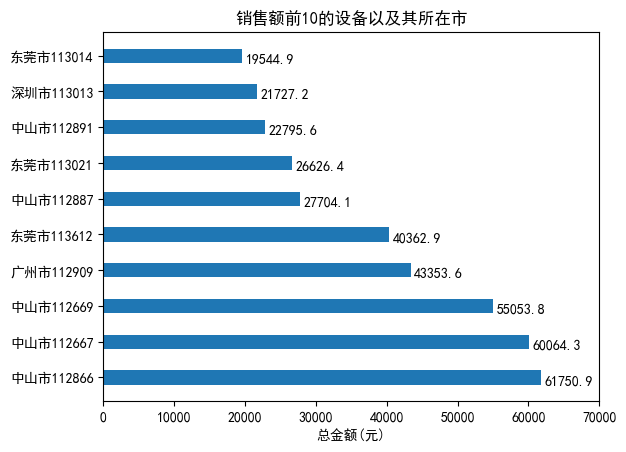

In [20]:
# 绘制各自动售货机的销售总金额
group6 = data.groupby(by=['市', '设备编号'], as_index=False)['总金额(元)'].sum()
group6.sort_values(by='总金额(元)', ascending=False, inplace=True)
b = group6[: 10]
label = []
# 销售额前10的设备编号以及所在市
for i in range(len(b)):
    a=b.iloc[i, 0] + str(b.iloc[i, 1])
    label.append(a)
x = np.round(b['总金额(元)'], 2).values.tolist()
y = range(10)
plt.bar(x=0, bottom=y, height=0.4, width=x, orientation='horizontal')
plt.xticks(range(0, 80000, 10000))  # 设置x轴的刻度范围
plt.yticks(range(10), label)
for y, x in enumerate(np.round(b['总金额(元)'], 2).values):
    plt.text(x + 500, y - 0.2, "%s" %x)
plt.xlabel('总金额(元)')
plt.title('销售额前10的设备以及其所在市')
plt.show()

### 3.10 新零售智能销售设备销售金额后 10

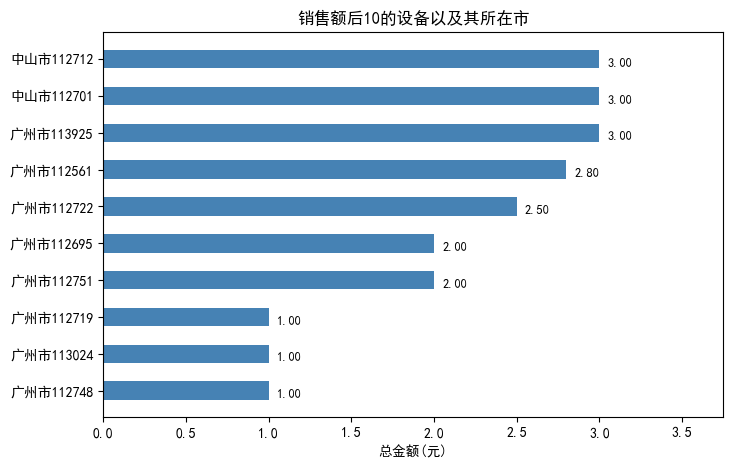

  市   设备编号  总金额(元)
广州市 112748     1.0
广州市 113024     1.0
广州市 112719     1.0
广州市 112751     2.0
广州市 112695     2.0
广州市 112722     2.5
广州市 112561     2.8
广州市 113925     3.0
中山市 112701     3.0
中山市 112712     3.0


In [21]:
# 3.10 绘制各新零售智能销售设备的销售总金额后10
# 按“市 + 设备编号”汇总销售额，升序排序后取销售额最低的10台设备
plt.rcParams['font.sans-serif'] = ['SimHei']   # 正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False     # 正常显示负号
group7 = data.groupby(by=['市', '设备编号'], as_index=False)['总金额(元)'].sum()
group7.sort_values(by='总金额(元)', ascending=True, inplace=True)
b = group7.iloc[: 10]                          # 销售额后10的设备
# 设备标签 = 所在市 + 设备编号
label = [b.iloc[i, 0] + str(b.iloc[i, 1]) for i in range(len(b))]
x = np.round(b['总金额(元)'].values, 2)
y = range(len(b))
plt.figure(figsize=(8, 5))
plt.barh(y=y, width=x, height=0.5, color='#4682B4')
plt.xlim(0, x.max() * 1.25)                    # 右侧留白放数值标注
for i, v in enumerate(x):
    plt.text(v + 0.05, i - 0.2, '%.2f' % v, fontsize=9)
plt.yticks(y, label)
plt.xlabel('总金额(元)')
plt.title('销售额后10的设备以及其所在市')
plt.savefig('图片/3.10.png', dpi=150, bbox_inches='tight')
plt.show()
# 结论：后10名中广州8台、中山2台，广州112748、113024、112719三台仅1元
print(b[['市', '设备编号', '总金额(元)']].to_string(index=False))

### 3.11 各市销售金额低于 100 元的设备数量

低效设备（销售额<100元）共 93 台，各市分布为：
   市  低效设备数量
广州市      52
中山市      20
佛山市      10
东莞市       6
清远市       2
深圳市       1
珠海市       1
韶关市       1


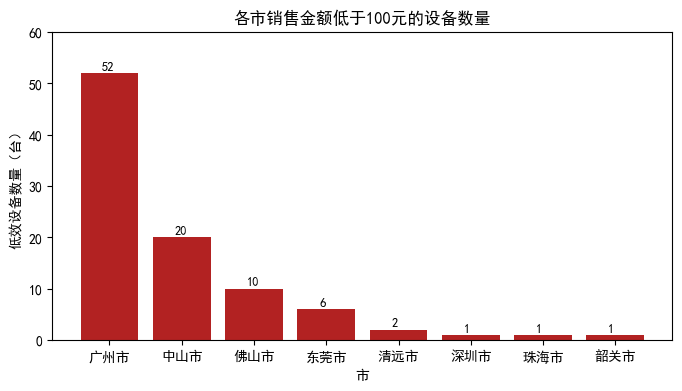

In [22]:
# 3.11 统计各城市销售金额小于100元的设备数量
# 先按“市 + 设备编号”汇总每台设备6个月的销售总额，再筛出低效设备（<100元）
group7 = data.groupby(by=['市', '设备编号'], as_index=False)['总金额(元)'].sum()
low = group7[group7['总金额(元)'] < 100]        # 销售金额低于100元的设备
low_cnt = low.groupby(by='市', as_index=False)['设备编号'].count()
low_cnt.columns = ['市', '低效设备数量']
low_cnt.sort_values(by='低效设备数量', ascending=False, inplace=True)
print('低效设备（销售额<100元）共', len(low), '台，各市分布为：\n', low_cnt.to_string(index=False))
plt.figure(figsize=(8, 4))
plt.bar(low_cnt['市'].values.tolist(), low_cnt['低效设备数量'].values.tolist(), color='#B22222')
for i, v in enumerate(low_cnt['低效设备数量'].values):
    plt.text(i - 0.1, v + 0.6, '%d' % v, fontsize=9)   # 数据标注
plt.yticks(range(0, 61, 10))
plt.xlabel('市')
plt.ylabel('低效设备数量（台）')
plt.title('各市销售金额低于100元的设备数量')
plt.savefig('图片/3.11.png', dpi=150, bbox_inches='tight')
plt.show()
# 结论：广州52台最多，中山20台，低效设备已覆盖全部8个市，提示点位摆放不合理

### 3.12 售罄率分析

 月份  销售数量   进货数量    售罄率
  4  2059  13812 0.1491
  5 42881 129521 0.3311
  6 42134 256819 0.1641
  7 45396 375190 0.1210
  8 46585 413085 0.1128
  9 51046 290972 0.1754


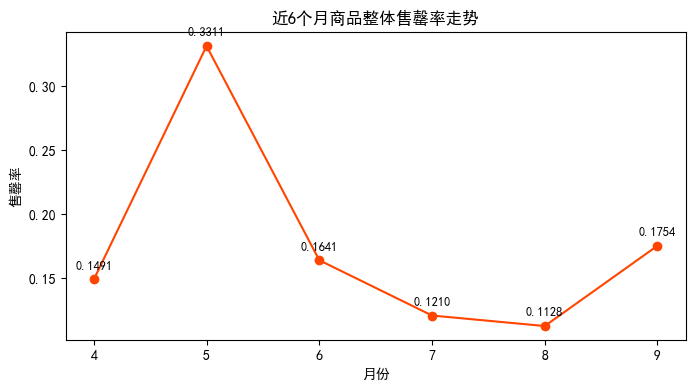

In [23]:
# 3.12 计算售罄率：售罄率 = 销售量 / 进货量（反映商品的销售速度）
goods = pd.read_csv('tmp/goods_info.csv', encoding='gbk')
# 先按月份汇总各商品的销售数量与进货数量，再计算整体售罄率
group8 = goods.groupby(by='月份', as_index=False)[['销售数量', '进货数量']].sum()
group8['售罄率'] = np.round(group8['销售数量'] / group8['进货数量'], 4)
print(group8.to_string(index=False))
plt.figure(figsize=(8, 4))
plt.plot(group8['月份'], group8['售罄率'], marker='o', color='#FF4500')
for m, r in zip(group8['月份'], group8['售罄率']):
    plt.text(m, r + 0.008, '%.4f' % r, ha='center', fontsize=9)
plt.xticks(group8['月份'])
plt.xlabel('月份')
plt.ylabel('售罄率')
plt.title('近6个月商品整体售罄率走势')
plt.savefig('图片/3.12.png', dpi=150, bbox_inches='tight')
plt.show()
# 结论：5月售罄率最高0.3311，其余月份仅0.11~0.18，整体动销不足

### 3.13 库存成本分析

 月份       库存成本
  4   47148.21
  5  587136.37
  6 1306673.24
  7 1529979.66
  8 1838731.12
  9 1351507.64


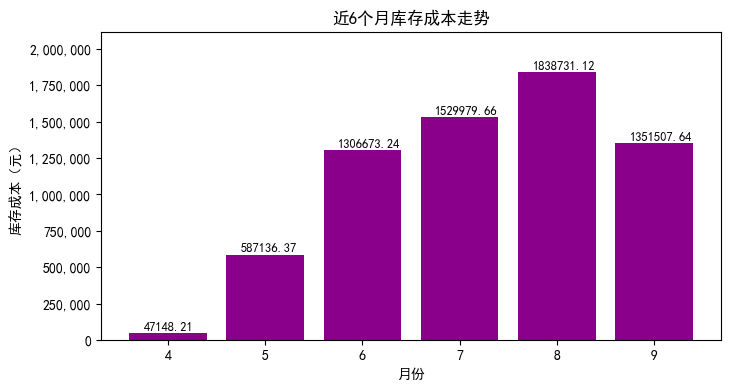

In [24]:
# 3.13 计算各个月库存成本：库存成本 = 销售单价 * 库存量
goods = pd.read_csv('tmp/goods_info.csv', encoding='gbk')
# 销售单价 = 销售金额 / 销售数量；当月销售数量为0时无法求单价，
# 用该商品6个月的“总销售金额 / 总销售数量”作为平均单价替代
goods['销售单价'] = np.nan
exp = goods['销售数量'] > 0
goods.loc[exp, '销售单价'] = goods.loc[exp, '销售金额'] / goods.loc[exp, '销售数量']
avg_price = (goods.groupby('商品名称')['销售金额'].sum() /
             goods.groupby('商品名称')['销售数量'].sum())
avg_price = avg_price.replace([np.inf, -np.inf], np.nan).fillna(0)
goods['销售单价'] = goods['销售单价'].fillna(goods['商品名称'].map(avg_price))
# 库存成本 = 销售单价 * 库存数量
goods['库存成本'] = np.round(goods['销售单价'] * goods['库存数量'], 2)
group9 = goods.groupby(by='月份', as_index=False)['库存成本'].sum()
group9['库存成本'] = np.round(group9['库存成本'], 2)
print(group9.to_string(index=False))
plt.figure(figsize=(8, 4))
plt.bar(group9['月份'].astype(str), group9['库存成本'], color='#8B008B')
for i, v in enumerate(group9['库存成本'].values):
    plt.text(i - 0.25, v + 20000, '%.2f' % v, fontsize=9)
# 以千分位显示金额刻度，避免科学计数法影响读数
plt.gca().yaxis.set_major_formatter(lambda v, p: format(int(v), ','))
plt.ylim(0, group9['库存成本'].max() * 1.15)
plt.xlabel('月份')
plt.ylabel('库存成本（元）')
plt.title('近6个月库存成本走势')
plt.savefig('图片/3.13.png', dpi=150, bbox_inches='tight')
plt.show()
# 结论：库存成本逐月走高，9月最高达1351507.64元，库存积压占用资金严重

### 3.14 进货数量、库存数量与销售数量走势

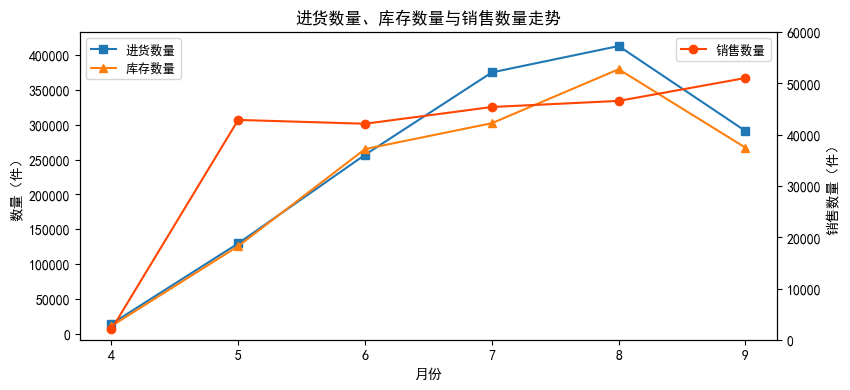

In [25]:
# 3.14 各个月进货数量、库存数量与销售数量的折线图
goods = pd.read_csv('tmp/goods_info.csv', encoding='gbk')
group10 = goods.groupby(by='月份', as_index=False)[['进货数量', '库存数量', '销售数量']].sum()
# 进货量、库存量量级相近放在左轴，销售量偏小放在右轴，便于观察走势关系
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(group10['月份'], group10['进货数量'], marker='s', label='进货数量')
ax1.plot(group10['月份'], group10['库存数量'], marker='^', label='库存数量')
ax1.set_xticks(group10['月份'])
ax1.set_xlabel('月份')
ax1.set_ylabel('数量（件）')
ax1.legend(loc='upper left', fontsize=9)
ax2 = ax1.twinx()                             # 创建第二个坐标轴
ax2.plot(group10['月份'], group10['销售数量'], marker='o', color='#FF4500', label='销售数量')
ax2.set_ylabel('销售数量（件）')
ax2.set_ylim(0, 60000)
ax2.legend(loc='upper right', fontsize=9)
plt.title('进货数量、库存数量与销售数量走势')
plt.savefig('图片/3.14.png', dpi=150, bbox_inches='tight')
plt.show()
# 结论：库存量与进货量走势基本一致（8月最高、4月最低），
#       而销售量5月后维持低位，进货多销售少直接造成库存积压

### 3.15 用户支付方式分析

         订单数  占比(%)
支付状态               
微信    312089  89.05
支付宝    34576   9.87
现金      3465   0.99
会员余额     320   0.09


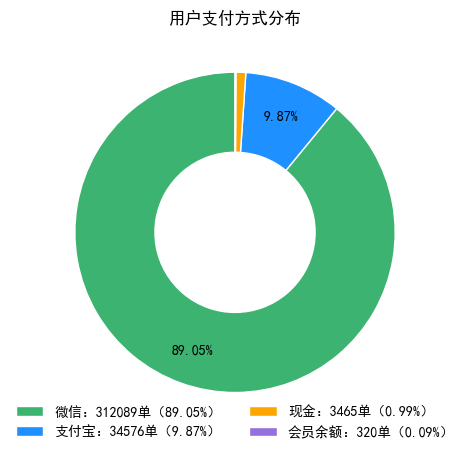

In [26]:
# 3.15 用户支付方式饼图
pay = data['支付状态'].value_counts()            # 各支付方式的订单数
pct = np.round(pay / pay.sum() * 100, 2)         # 各支付方式占比（%）
print(pd.DataFrame({'订单数': pay, '占比(%)': pct}).to_string())
plt.figure(figsize=(6.5, 5.2))
wedges, _, autotexts = plt.pie(
    pay.values, startangle=90,
    colors=['#3CB371', '#1E90FF', '#FFA500', '#9370DB'],
    # 只在占比≥1%的扇区内标注百分比；现金、会员余额占比不足1%，改由右侧图例说明，
    # 避免极小扇区的标签互相遮挡
    autopct=lambda p: '%.2f%%' % p if p >= 1 else '',
    pctdistance=0.78,
    wedgeprops={'width': 0.5, 'edgecolor': 'w'})
# 扇区名称与单量统一放到右侧图例中
plt.legend(wedges, ['%s：%d单（%.2f%%）' % (k, v, p)
                    for k, v, p in zip(pay.index, pay.values, pct)],
           loc='upper center', bbox_to_anchor=(0.5, 0.10), ncol=2,
           frameon=False, fontsize=10)
plt.title('用户支付方式分布')
plt.savefig('图片/3.15.png', dpi=150, bbox_inches='tight')
plt.show()
# 结论：微信支付89.05%为绝对主流，支付宝9.87%，现金与会员余额合计不足1.1%

### 3.16 用户所在城市分析

  市   用户数量    占比
清远市    138  0.04
韶关市   4142  1.18
珠海市  12589  3.59
深圳市  13731  3.92
佛山市  16398  4.68
东莞市  82182 23.45
中山市  84738 24.18
广州市 136532 38.96
前三市合计占比：86.59%


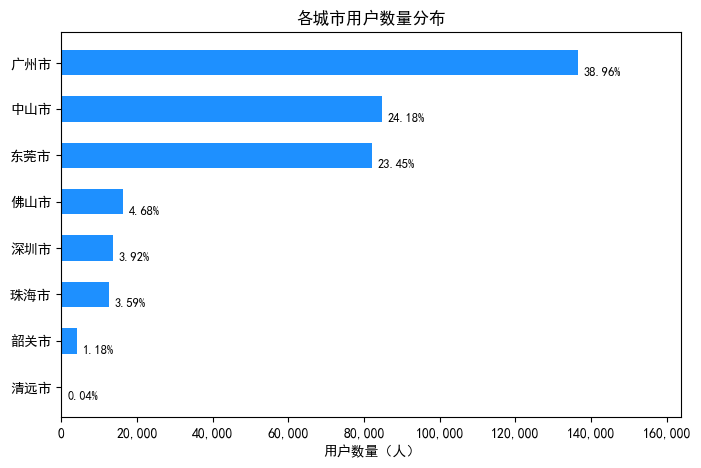

In [27]:
# 3.16 用户所在城市分析
# 订单表中每一单记录一次购买行为，按订单数统计各市用户购买量分布
group11 = data.groupby(by='市', as_index=False)['购买用户'].count()
group11.columns = ['市', '用户数量']
group11['占比'] = np.round(group11['用户数量'] / group11['用户数量'].sum() * 100, 2)
group11.sort_values(by='用户数量', ascending=True, inplace=True)
print(group11.to_string(index=False))
print('前三市合计占比：%.2f%%' % group11['占比'].nlargest(3).sum())
plt.figure(figsize=(8, 5))
plt.barh(group11['市'], group11['用户数量'], height=0.55, color='#1E90FF')
for i, (u, p) in enumerate(zip(group11['用户数量'], group11['占比'])):
    plt.text(u + 1500, i - 0.2, '%.2f%%' % p, fontsize=9, va='center')
plt.xlim(0, group11['用户数量'].max() * 1.2)
plt.gca().xaxis.set_major_formatter(lambda v, p: format(int(v), ','))  # 千分位刻度
plt.xlabel('用户数量（人）')
plt.title('各城市用户数量分布')
plt.savefig('图片/3.16.png', dpi=150, bbox_inches='tight')
plt.show()
# 结论：广州136532人最多，中山、东莞次之，三市合计占86.59%；清远最少仅0.04%

### 3.17 用户消费时段分析

下单时间段
凌晨     7.62
早晨     7.25
上午    17.08
中午    12.97
下午    21.44
傍晚    16.27
晚上    17.36


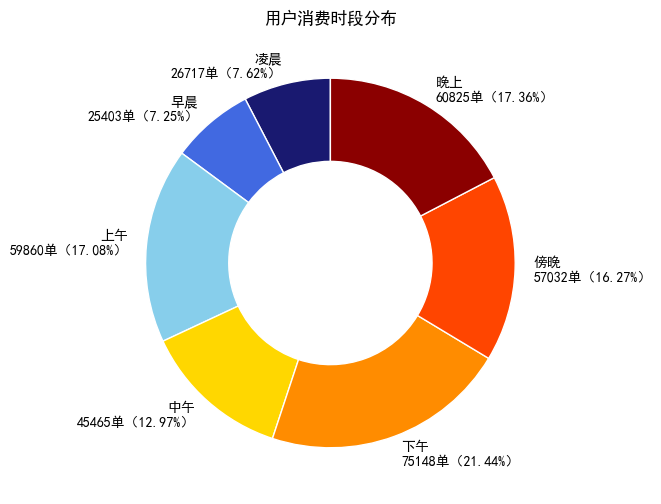

In [28]:
# 3.17 绘制用户的消费时段饼图（下单时间段由“下单时间”规约得到）
seg = data['下单时间段'].value_counts()
order = ['凌晨', '早晨', '上午', '中午', '下午', '傍晚', '晚上']   # 按时间先后排序
seg = seg.reindex(order)
print((seg / seg.sum() * 100).round(2).to_string())
plt.figure(figsize=(7, 6))
plt.pie(seg.values,
        labels=['%s\n%d单（%.2f%%）' % (k, v, v / seg.sum() * 100)
                for k, v in zip(seg.index, seg.values)],
        autopct='', startangle=90,
        colors=['#191970', '#4169E1', '#87CEEB', '#FFD700', '#FF8C00', '#FF4500', '#8B0000'],
        wedgeprops={'width': 0.45, 'edgecolor': 'w'})
plt.title('用户消费时段分布')
plt.savefig('图片/3.17.png', dpi=150, bbox_inches='tight')
plt.show()
# 结论：下午21.44%为消费高峰，晚上17.36%、上午17.08%、傍晚16.27%次之，
#       凌晨（7.62%）与早晨（7.25%）最少，适合安排补货